# Покращення DQN для CarRacing-v3

| Крок | Зміна |
|---|---|
| 0 | Бейзлайн | точка відліку |
| 1 | Double DQN + Dueling head | менше завищення Q, краща оцінка стану "на трасі" |
| 2 | Soft (Polyak) target update + n-step (n=3) | стабільніші цілі, швидше поширення нагороди (тайл-нагорода +1000/N) |
| 3 | Random-shift augmentation | регуляризація для піксельного входу, менше перенавчання на буфері |
| 4 | Відбір чекпоінта за greedy-оцінкою | бейзлайн зберігає "найкращий avg100" епсилон-жадібної політики — це шумний критерій, тестується ж greedy-політика |
| 5 | Фінальний довгий запуск + перевірка незмінним `test_car_racing.py` | |


In [ ]:
import os, sys, json, shutil, subprocess, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

RAW = "https://raw.githubusercontent.com/PavloZakala/ReinforcementLearning/main/"
for fname in ["test_car_racing.py", "checkpoint_CarRacing-v3_best.pth"]:
    if not os.path.exists(fname):
        urllib.request.urlretrieve(RAW + fname, fname)
        print("downloaded", fname)
os.makedirs("runs", exist_ok=True)
shutil.copy("checkpoint_CarRacing-v3_best.pth", "runs/baseline_given.pth")

'runs/baseline_given.pth'

## Baseline Test

In [19]:
def run_test_script(ckpt, episodes=50, dueling=True):
    env = dict(os.environ, DQN_DUELING="1" if dueling else "0")
    out = subprocess.run([sys.executable, "test_car_racing.py", ckpt, str(episodes)],
                         env=env, capture_output=True, text=True)
    print(out.stdout[-300:] + out.stderr[-500:])
    stats = {}
    for line in out.stdout.splitlines():
        for k in ["Mean", "Std", "Min", "Max"]:
            if line.startswith(k):
                stats[k] = float(line.split(":")[1])
    return stats

baseline_stats = run_test_script("checkpoint_CarRacing-v3_best.pth", 50, dueling=False)
baseline_stats   # очікується ~ Mean 840.6, Std 103.2, Min 470.4, Max 912.7

rd 698.2
Episode 44	Reward 719.0
Episode 45	Reward 909.6
Episode 46	Reward 910.1
Episode 47	Reward 857.7
Episode 48	Reward 444.8
Episode 49	Reward 888.7
Episode 50	Reward 906.7
----------------------------------------
Episodes : 50
Mean     : 772.3
Std      : 183.6
Min      : 303.8
Max      : 920.5
s the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  policy.load_state_dict(torch.load(checkpoint, map_location=device))



{'Mean': 772.3, 'Std': 183.6, 'Min': 303.8, 'Max': 920.5}

In [6]:
import importlib, dqn_car_racing as D
importlib.reload(D)
from dataclasses import replace

ABL_EPISODES   = 150
FINAL_EPISODES = 1000    # фінальний запуск
SEED = 0

def base_cfg(name, n_episodes, **kw):
    return D.Config(name=name, n_episodes=n_episodes, seed=SEED,
                    epsilon_decay=D.eps_decay_for(n_episodes), validate_every=25, eval_episodes=5, **kw)

results = {}   # name -> dict(paths, log)

def run(cfg):
    paths = D.train(cfg)
    results[cfg.name] = paths
    return paths

def load_log(name):
    return json.load(open(f"runs/{name}.json"))

def plot_runs(names, title):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for n in names:
        lg = load_log(n)
        tr = pd.DataFrame(lg["train"]); ev = pd.DataFrame(lg["eval"])
        ax[0].plot(tr["episode"], tr["avg100"], label=n)
        ax[1].plot(ev["episode"], ev["mean"], marker="o", ms=3, label=n)
    ax[0].set_title("train avg100 (ε-greedy)"); ax[1].set_title("greedy eval, mean of 5 episodes")
    for a in ax: a.set_xlabel("episode"); a.legend(); a.grid(alpha=.3)
    fig.suptitle(title); plt.show()

def summary(names):
    rows = []
    for n in names:
        lg = load_log(n); ev = pd.DataFrame(lg["eval"])
        rows.append({"run": n, "best greedy eval": ev["mean"].max(),
                     "last-5 eval mean": ev["mean"].tail(5).mean(), "minutes": lg.get("minutes", np.nan)})
    return pd.DataFrame(rows).set_index("run").round(1)

### Step 0 - baseline

[s0_baseline] ep 1	score   -62.4	avg100   -62.4	eps 0.967
[s0_baseline] ep 2	score   -52.7	avg100   -57.6	eps 0.936
[s0_baseline] ep 3	score   -52.2	avg100   -55.8	eps 0.905
[s0_baseline] ep 4	score   -52.0	avg100   -54.8	eps 0.875
[s0_baseline] ep 5	score   -52.7	avg100   -54.4	eps 0.847
[s0_baseline] ep 6	score   -57.4	avg100   -54.9	eps 0.819
[s0_baseline] ep 7	score   -50.7	avg100   -54.3	eps 0.792
[s0_baseline] ep 8	score   -68.7	avg100   -56.1	eps 0.766
[s0_baseline] ep 9	score   -53.7	avg100   -55.8	eps 0.741
[s0_baseline] ep 10	score   -60.5	avg100   -56.3	eps 0.717
[s0_baseline] ep 11	score   -51.0	avg100   -55.8	eps 0.693
[s0_baseline] ep 12	score   -57.1	avg100   -55.9	eps 0.671
[s0_baseline] ep 13	score   -49.7	avg100   -55.5	eps 0.649
[s0_baseline] ep 14	score   -48.7	avg100   -55.0	eps 0.628
[s0_baseline] ep 15	score   -51.4	avg100   -54.7	eps 0.607
[s0_baseline] ep 16	score   -50.6	avg100   -54.5	eps 0.587
[s0_baseline] ep 17	score   -53.6	avg100   -54.4	eps 0.568
[s0_ba

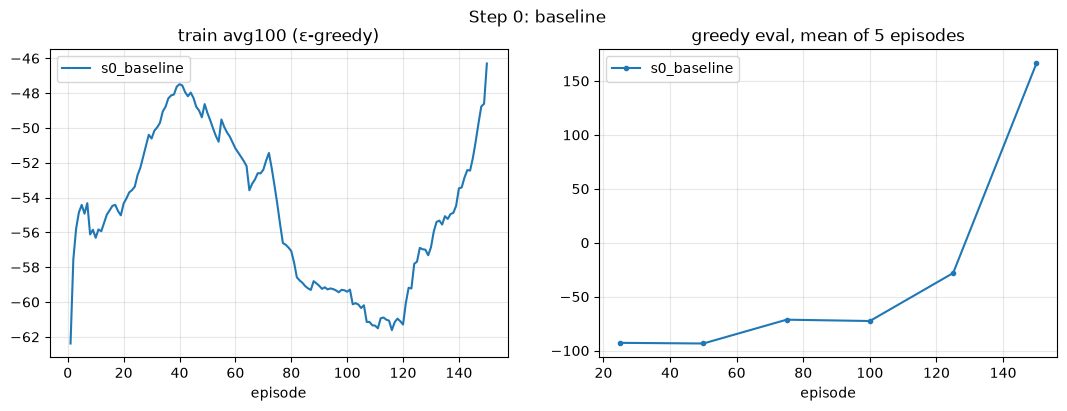

In [7]:
run(base_cfg("s0_baseline", ABL_EPISODES))
plot_runs(["s0_baseline"], "Step 0: baseline")

### Step 1 - Double DQN + Dueling

[s1_double_dueling] ep 1	score   -62.4	avg100   -62.4	eps 0.967
[s1_double_dueling] ep 2	score   -52.7	avg100   -57.6	eps 0.936
[s1_double_dueling] ep 3	score   -52.2	avg100   -55.8	eps 0.905
[s1_double_dueling] ep 4	score   -52.0	avg100   -54.8	eps 0.875
[s1_double_dueling] ep 5	score   -52.7	avg100   -54.4	eps 0.847
[s1_double_dueling] ep 6	score   -57.4	avg100   -54.9	eps 0.819
[s1_double_dueling] ep 7	score   -50.7	avg100   -54.3	eps 0.792
[s1_double_dueling] ep 8	score   -68.7	avg100   -56.1	eps 0.766
[s1_double_dueling] ep 9	score   -50.2	avg100   -55.5	eps 0.741
[s1_double_dueling] ep 10	score   -54.8	avg100   -55.4	eps 0.717
[s1_double_dueling] ep 11	score   -51.0	avg100   -55.0	eps 0.693
[s1_double_dueling] ep 12	score   -57.1	avg100   -55.2	eps 0.671
[s1_double_dueling] ep 13	score   -46.5	avg100   -54.5	eps 0.649
[s1_double_dueling] ep 14	score   -52.4	avg100   -54.4	eps 0.628
[s1_double_dueling] ep 15	score   -51.4	avg100   -54.2	eps 0.607
[s1_double_dueling] ep 16	score   

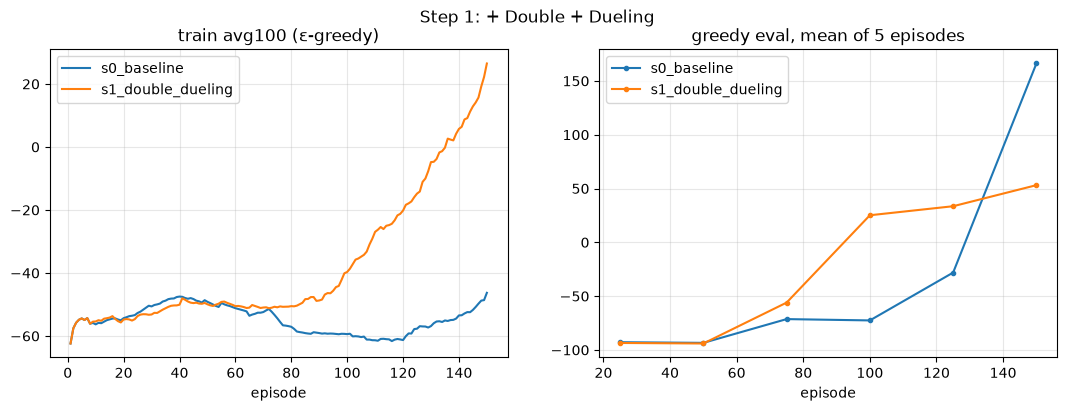

,best greedy eval,last-5 eval mean,minutes
run,,,
s0_baseline,166.2,-19.8,36.9
s1_double_dueling,53.1,-7.6,36.7


In [8]:
run(base_cfg("s1_double_dueling", ABL_EPISODES, double=True, dueling=True))
plot_runs(["s0_baseline", "s1_double_dueling"], "Step 1: + Double + Dueling")
summary(["s0_baseline", "s1_double_dueling"])

### Step 2 - Soft target update (τ=0.005) + n-step (n=3)

[s2_soft_nstep] ep 1	score   -62.4	avg100   -62.4	eps 0.967
[s2_soft_nstep] ep 2	score   -56.4	avg100   -59.4	eps 0.936
[s2_soft_nstep] ep 3	score   -52.2	avg100   -57.0	eps 0.905
[s2_soft_nstep] ep 4	score   -52.0	avg100   -55.8	eps 0.875
[s2_soft_nstep] ep 5	score   -49.1	avg100   -54.4	eps 0.847
[s2_soft_nstep] ep 6	score   -57.4	avg100   -54.9	eps 0.819
[s2_soft_nstep] ep 7	score   -50.7	avg100   -54.3	eps 0.792
[s2_soft_nstep] ep 8	score   -59.2	avg100   -54.9	eps 0.766
[s2_soft_nstep] ep 9	score   -39.5	avg100   -53.2	eps 0.741
[s2_soft_nstep] ep 10	score   -52.0	avg100   -53.1	eps 0.717
[s2_soft_nstep] ep 11	score   -26.6	avg100   -50.7	eps 0.693
[s2_soft_nstep] ep 12	score   -47.2	avg100   -50.4	eps 0.671
[s2_soft_nstep] ep 13	score   -37.1	avg100   -49.4	eps 0.649
[s2_soft_nstep] ep 14	score   -41.4	avg100   -48.8	eps 0.628
[s2_soft_nstep] ep 15	score   -44.4	avg100   -48.5	eps 0.607
[s2_soft_nstep] ep 16	score   -43.0	avg100   -48.2	eps 0.587
[s2_soft_nstep] ep 17	score   -31

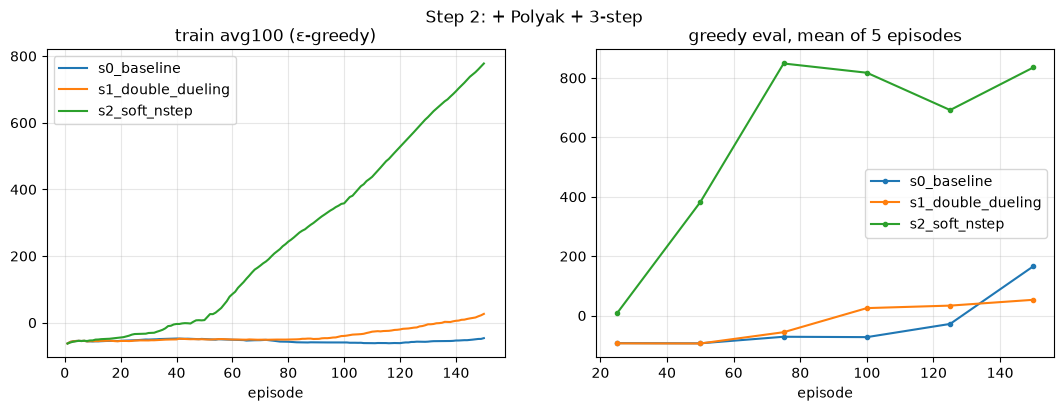

,best greedy eval,last-5 eval mean,minutes
run,,,
s0_baseline,166.2,-19.8,36.9
s1_double_dueling,53.1,-7.6,36.7
s2_soft_nstep,848.8,715.3,31.1


In [9]:
run(base_cfg("s2_soft_nstep", ABL_EPISODES, double=True, dueling=True, tau=0.005, n_step=3))
plot_runs(["s0_baseline", "s1_double_dueling", "s2_soft_nstep"], "Step 2: + Polyak + 3-step")
summary(["s0_baseline", "s1_double_dueling", "s2_soft_nstep"])

### Step 3 - Random-shift augmentation (±4 px)

[s3_aug] ep 1	score   -62.4	avg100   -62.4	eps 0.967
[s3_aug] ep 2	score   -56.4	avg100   -59.4	eps 0.936
[s3_aug] ep 3	score   -52.2	avg100   -57.0	eps 0.905
[s3_aug] ep 4	score   -52.0	avg100   -55.8	eps 0.875
[s3_aug] ep 5	score   -49.1	avg100   -54.4	eps 0.847
[s3_aug] ep 6	score   -57.4	avg100   -54.9	eps 0.819
[s3_aug] ep 7	score   -50.7	avg100   -54.3	eps 0.792
[s3_aug] ep 8	score   -59.2	avg100   -54.9	eps 0.766
[s3_aug] ep 9	score   -32.4	avg100   -52.4	eps 0.741
[s3_aug] ep 10	score   -43.5	avg100   -51.5	eps 0.717
[s3_aug] ep 11	score   -33.6	avg100   -49.9	eps 0.693
[s3_aug] ep 12	score   -43.9	avg100   -49.4	eps 0.671
[s3_aug] ep 13	score   -40.3	avg100   -48.7	eps 0.649
[s3_aug] ep 14	score   -37.7	avg100   -47.9	eps 0.628
[s3_aug] ep 15	score   -37.5	avg100   -47.2	eps 0.607
[s3_aug] ep 16	score   -39.2	avg100   -46.7	eps 0.587
[s3_aug] ep 17	score   -31.9	avg100   -45.8	eps 0.568
[s3_aug] ep 18	score   -31.4	avg100   -45.0	eps 0.549
[s3_aug] ep 19	score   -32.4	avg100  

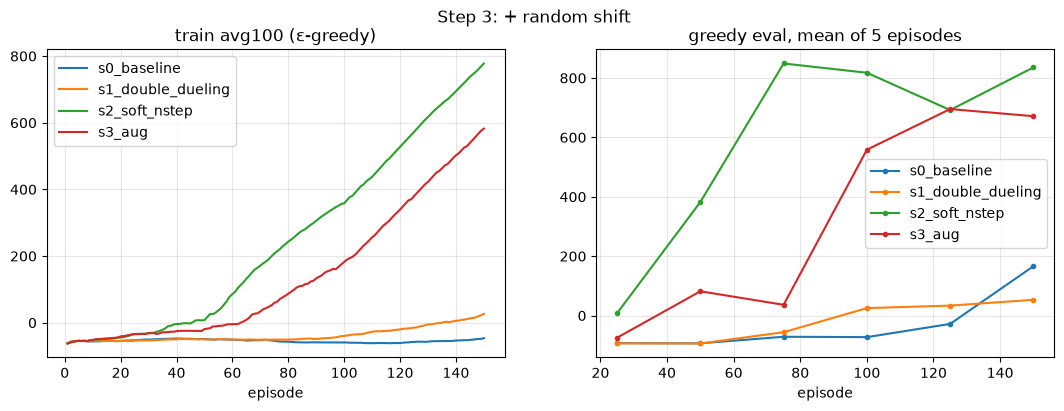

,best greedy eval,last-5 eval mean,minutes
run,,,
s0_baseline,166.2,-19.8,36.9
s1_double_dueling,53.1,-7.6,36.7
s2_soft_nstep,848.8,715.3,31.1
s3_aug,695.3,408.6,31.8


In [10]:
run(base_cfg("s3_aug", ABL_EPISODES, double=True, dueling=True, tau=0.005, n_step=3, aug_pad=4))
names = ["s0_baseline", "s1_double_dueling", "s2_soft_nstep", "s3_aug"]
plot_runs(names, "Step 3: + random shift")
summary(names)

### Відбір чекпоінта

Бейзлайн зберігає ваги за найкращим `avg100` **епсилон-жадібної** політики; тестується ж greedy-політика, тому критерій шумний і зміщений.
Ми зберігаємо `best_eval` та top-k кандидатів за greedy-оцінкою, а потім перевіряємо кандидатів на нових епізодах. Порівняємо правила на уже натренованому кроці 3:

In [11]:
r = results["s3_aug"]
cands = {"best_train (baseline rule)": r["best_train"], "best_eval (greedy rule)": r["best_eval"], "last": r["last"]}
sel = {}
for k, p in cands.items():
    print("==", k)
    sel[k] = D.select_best([p], n_episodes=20)[0][0]
pd.Series(sel, name="mean over 20 fresh episodes").round(1)

== best_train (baseline rule)


c:\Users\Naturemant\Uni\ReinforcementLearning\dqn_car_racing.py:347: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  m.load_state_dict(torch.load(p, map_location=device))


s3_aug_best_train.pth: mean 737.3  std 136.1  min 459.4
== best_eval (greedy rule)
s3_aug_best_eval.pth: mean 640.7  std 120.9  min 408.2
== last
s3_aug_last.pth: mean 708.1  std 171.3  min 373.5


best_train (baseline rule)    737.3
best_eval (greedy rule)       640.7
last                          708.1
Name: mean over 20 fresh episodes, dtype: float64

## Step 4 - final run
(аугментація прибрана оскільки вона дала гірші результати за попередні)

[final] ep 1	score   -62.4	avg100   -62.4	eps 0.995
[final] ep 2	score   -56.4	avg100   -59.4	eps 0.990
[final] ep 3	score   -52.2	avg100   -57.0	eps 0.985
[final] ep 4	score   -52.0	avg100   -55.8	eps 0.980
[final] ep 5	score   -49.1	avg100   -54.4	eps 0.975
[final] ep 6	score   -57.4	avg100   -54.9	eps 0.970
[final] ep 7	score   -50.7	avg100   -54.3	eps 0.966
[final] ep 8	score   -59.2	avg100   -54.9	eps 0.961
[final] ep 9	score   -53.7	avg100   -54.8	eps 0.956
[final] ep 10	score   -60.5	avg100   -55.4	eps 0.951
[final] ep 11	score   -51.0	avg100   -55.0	eps 0.947
[final] ep 12	score   -57.1	avg100   -55.2	eps 0.942
[final] ep 13	score   -62.3	avg100   -55.7	eps 0.937
[final] ep 14	score   -48.7	avg100   -55.2	eps 0.932
[final] ep 15	score   -58.3	avg100   -55.4	eps 0.928
[final] ep 16	score   -58.2	avg100   -55.6	eps 0.923
[final] ep 17	score   -56.7	avg100   -55.6	eps 0.919
[final] ep 18	score   -54.2	avg100   -55.6	eps 0.914
[final] ep 19	score   -49.3	avg100   -55.2	eps 0.909
[f

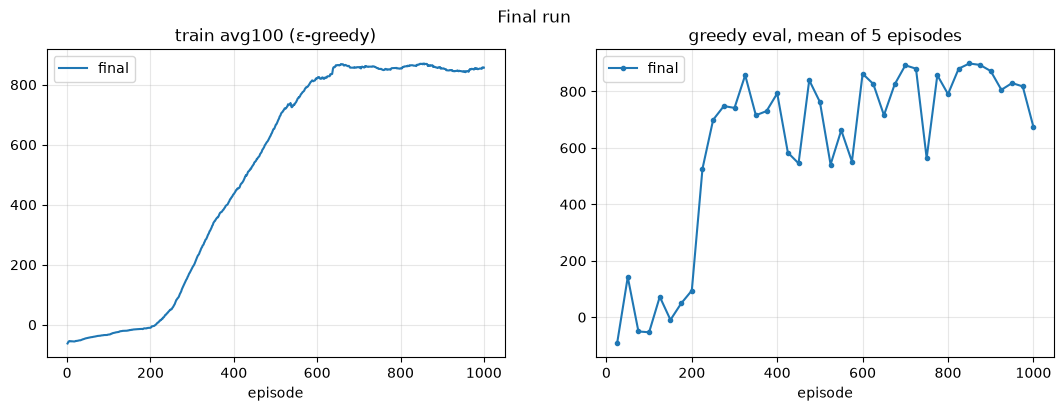

In [13]:
FINAL_KW = dict(double=True, dueling=True, tau=0.005, n_step=3, aug_pad=0)
final_cfg = base_cfg("final", FINAL_EPISODES, top_k=5, **FINAL_KW)
run(final_cfg)
plot_runs(["final"], "Final run")

### Відбір + перевірка `test_car_racing.py`
Кандидати (top-k за greedy-оцінкою) переоцінюються на 20 нових епізодах; найкращий копіюється у `checkpoint_CarRacing-v3_improved.pth` і тестується базовим скриптом на 50 епізодах

In [16]:
cand_paths = results["final"]["top"] + [results["final"]["best_eval"], results["final"]["last"]]
ranking = D.select_best(list(dict.fromkeys(cand_paths)), n_episodes=10, dueling=final_cfg.dueling)
best_path = ranking[0][1]
shutil.copy(best_path, "checkpoint_CarRacing-v3_improved.pth")
print("selected:", best_path)

improved_stats = run_test_script("checkpoint_CarRacing-v3_improved.pth", 50, dueling=final_cfg.dueling)
improved_stats

c:\Users\Naturemant\Uni\ReinforcementLearning\dqn_car_racing.py:347: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  m.load_state_dict(torch.load(p, map_location=device))


final_ep850_eval899.pth: mean 784.1  std 181.8  min 415.9
final_ep875_eval894.pth: mean 838.2  std 130.3  min 513.2
final_ep700_eval893.pth: mean 802.1  std 155.1  min 451.0
final_ep825_eval881.pth: mean 761.8  std 220.7  min 207.2
final_ep725_eval881.pth: mean 886.9  std 20.4  min 839.3
final_best_eval.pth: mean 849.0  std 127.6  min 475.9
final_last.pth: mean 858.8  std 67.7  min 718.1
selected: runs\checkpoints\final_ep725_eval881.pth
rd 896.5
Episode 44	Reward 843.1
Episode 45	Reward 598.5
Episode 46	Reward 874.8
Episode 47	Reward 856.0
Episode 48	Reward 887.8
Episode 49	Reward 893.3
Episode 50	Reward 871.6
----------------------------------------
Episodes : 50
Mean     : 827.9
Std      : 137.8
Min      : 227.4
Max      : 925.3
s the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `we

{'Mean': 827.9, 'Std': 137.8, 'Min': 227.4, 'Max': 925.3}

## 5. Підсумок

In [17]:
tbl = pd.DataFrame({"baseline (given ckpt)": baseline_stats, "improved": improved_stats}).T
tbl["Δ Mean"] = tbl["Mean"] - baseline_stats["Mean"]
display(tbl.round(1))

abl = summary(["s0_baseline", "s1_double_dueling", "s2_soft_nstep", "s3_aug"])
display(abl)

,Mean,Std,Min,Max,Δ Mean
baseline (given ckpt),784.1,179.7,270.8,917.5,0.0
improved,827.9,137.8,227.4,925.3,43.8


,best greedy eval,last-5 eval mean,minutes
run,,,
s0_baseline,166.2,-19.8,36.9
s1_double_dueling,53.1,-7.6,36.7
s2_soft_nstep,848.8,715.3,31.1
s3_aug,695.3,408.6,31.8


## Відео

In [23]:
import dqn_car_racing as D
D.render("checkpoint_CarRacing-v3_best.pth", num_episodes=3,
         video_folder="videos/baseline", dueling=False)
D.render("checkpoint_CarRacing-v3_improved.pth", num_episodes=3,
         video_folder="videos/improved", dueling=True)

c:\Users\Naturemant\miniforge3\envs\carracing\Lib\site-packages\gymnasium\wrappers\rendering.py:298: UserWarning: WARN: Overwriting existing videos at c:\Users\Naturemant\Uni\ReinforcementLearning\videos\baseline folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(
c:\Users\Naturemant\Uni\ReinforcementLearning\dqn_car_racing.py:476: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly al

Saved videos to videos/baseline/
Saved videos to videos/improved/
